# Analysis: does a larger amount of features improve the segmentation?

This notebook does all experiments on the features computed by `extract_features.py`.
Run that script first (once, and again after adding a feature). Everything here is plain numpy / scikit-learn:

1. Load the features
2. Choose the random forest (task 1)
3. Compare feature sets (task 2)
4. Feature importance with SHAP (task 3)
5. Feature selection with Boruta
6. Leave one feature group out (task 4)
7. Robustness to image noise (task 5)
8. Extended features vs the basic ones, with segmentations to look at (task 2)

A **feature set** is just a list of column names: `X[:, columns(names)]`. Nothing has to be recomputed to try another set.

In [2]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import SimpleITK as sitk
from scipy import stats
from sklearn.ensemble import RandomForestClassifier

import mialab.utilities.pipeline_utilities as putil

FEATURE_DIR = 'features'
ATLAS_FILE = '../data/atlas/mni_icbm152_t1_tal_nlin_sym_09a.nii.gz'
LABELS = {1: 'WhiteMatter', 2: 'GreyMatter', 3: 'Hippocampus', 4: 'Amygdala', 5: 'Thalamus'}

## 0. Load the features

- `train`: the randomly sampled training voxels of the 20 training subjects (about 5'000 per subject).
- `test`: one entry per test subject with **all** voxels inside the brain mask (about 1.8 million per subject).
  Voxels outside the brain mask are background, so they don't need a prediction.

In [5]:
def load_test(folder):
    """Loads all test subjects of a folder into a dict {subject: npz data}."""
    files = sorted(glob.glob(os.path.join(folder, 'test_*.npz')))
    return {os.path.basename(f)[5:-4]: dict(np.load(f)) for f in files}


train = np.load(os.path.join(FEATURE_DIR, 'train.npz'))
X_train, y_train = train['X'], train['y']
FEATURE_NAMES = list(train['feature_names'])
test = load_test(FEATURE_DIR)

print('features:', FEATURE_NAMES)
print('training voxels:', X_train.shape, ' test subjects:', list(test))
print('training voxels per label:', dict(zip(*np.unique(y_train, return_counts=True))))

features: ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2', 'T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY', 'T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY']
training voxels: (132880, 7)  test subjects: ['117122', '118528', '118730', '118932', '120111', '122317', '122620', '123117', '123925', '124422']
training voxels per label: {0: 45817, 1: 38969, 2: 31234, 3: 7091, 4: 2598, 5: 7171}


In [27]:
def columns(names):
    """Column indices of a list of feature names."""
    return [FEATURE_NAMES.index(n) for n in names]


def dice(prediction, truth, label):
    """Dice coefficient of one label: 2 |A and B| / (|A| + |B|)."""
    a, b = prediction == label, truth == label
    return 2 * np.sum(a & b) / (np.sum(a) + np.sum(b))


atlas = sitk.ReadImage(ATLAS_FILE)  # all images are registered to the atlas, so they share its geometry


def to_image(values, brain_index, dtype=np.uint8):
    """Puts the values of the brain voxels back into a full 3-D image (needed for HD95)."""
    volume = np.zeros(atlas.GetSize()[::-1], dtype=dtype)
    volume.flat[brain_index] = values
    image = sitk.GetImageFromArray(volume)
    image.CopyInformation(atlas)
    return image


evaluator = putil.init_evaluator()  # the pipeline's evaluator: Dice and HD95 (pymia)

In [28]:
def train_forest(names, seed=0, **forest_params):
    """Trains a random forest on the given feature columns."""
    params = dict(n_estimators=50, max_depth=20, max_features='sqrt', n_jobs=-1)
    params.update(forest_params)
    forest = RandomForestClassifier(random_state=seed, **params)
    forest.fit(X_train[:, columns(names)], y_train)
    return forest


def evaluate(forest, names, test_data=None, with_hd95=False, experiment=''):
    """Dice (and optionally HD95) per test subject and structure, as a table with one row per value."""
    rows = []
    for subject, data in (test_data or test).items():
        prediction = forest.predict(data['X'][:, columns(names)])
        if with_hd95:  # the pipeline's evaluator needs images
            evaluator.evaluate(to_image(prediction, data['brain_index']), to_image(data['y'], data['brain_index']),
                               subject)
            rows += [{'experiment': experiment, 'subject': subject, 'label': r.label, 'metric': r.metric,
                      'value': r.value} for r in evaluator.results]
            evaluator.clear()
        else:  # Dice only, computed directly with numpy (fast)
            rows += [{'experiment': experiment, 'subject': subject, 'label': name, 'metric': 'DICE',
                      'value': dice(prediction, data['y'], label)} for label, name in LABELS.items()]
    return pd.DataFrame(rows)


def summary(results):
    """Mean and std over the test subjects, one column per experiment."""
    table = results.groupby(['metric', 'label', 'experiment'])['value'].agg(['mean', 'std'])
    return (table['mean'].round(3).astype(str) + ' ± ' + table['std'].round(3).astype(str)).unstack()


def wilcoxon(results, baseline, other, metric='DICE'):
    """Paired Wilcoxon test per structure: is `other` different from `baseline`?"""
    rows = []
    for label in LABELS.values():
        r = results[(results.metric == metric) & (results.label == label)]
        a = r[r.experiment == baseline].sort_values('subject').value.values
        b = r[r.experiment == other].sort_values('subject').value.values
        rows.append({'label': label, 'median_diff': np.median(b - a),
                     'p_value': stats.wilcoxon(b, a).pvalue if np.any(a != b) else 1.0})
    return pd.DataFrame(rows)

## 1. Choose the random forest

The provided forest (1 tree, depth 5) is too weak: the amygdala is never predicted. Try a few settings on the
**provided features**, pick one with good Dice and acceptable run time, and keep it fixed for everything below.

In [29]:
BASELINE = ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2', 'T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY']

forest_results = []
for n_estimators, max_depth in [(10, 10), (50, 20), (100, 40)]:  # add more settings here, e.g. (100, 25), (100, None)
    forest = train_forest(BASELINE, n_estimators=n_estimators, max_depth=max_depth)
    forest_results.append(evaluate(forest, BASELINE, experiment=f'{n_estimators} trees, depth {max_depth}'))
forest_results = pd.concat(forest_results)
summary(forest_results)

experiment         10 trees, depth 10 100 trees, depth 40 50 trees, depth 20
metric label                                                                
DICE   Amygdala         0.492 ± 0.044       0.534 ± 0.046      0.523 ± 0.047
       GreyMatter       0.696 ± 0.011       0.717 ± 0.011      0.716 ± 0.011
       Hippocampus       0.375 ± 0.01       0.565 ± 0.018      0.532 ± 0.017
       Thalamus         0.728 ± 0.027       0.764 ± 0.024      0.763 ± 0.024
       WhiteMatter      0.814 ± 0.019       0.826 ± 0.019      0.826 ± 0.019

In [30]:
FOREST = dict(n_estimators=50, max_depth=20)  # the chosen setting: don't change it after this point

## 2. Compare feature sets

Each feature set is a list of names. Train with 3 seeds to see how much the result changes by chance alone.

In [31]:
FEATURE_SETS = {
    'baseline': BASELINE,
    'baseline + T2': BASELINE + ['T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY'],
    'all': FEATURE_NAMES,
}
SEEDS = [0, 1, 2]

results = []
for name, names in FEATURE_SETS.items():
    for seed in SEEDS:
        forest = train_forest(names, seed=seed, **FOREST)
        r = evaluate(forest, names, experiment=name)
        r['seed'] = seed
        results.append(r)
results = pd.concat(results)
# average the seeds per subject, so every subject counts once
results_mean = results.groupby(['experiment', 'subject', 'label', 'metric'], as_index=False)['value'].mean()
summary(results_mean)

experiment                    all       baseline  baseline + T2
metric label                                                   
DICE   Amygdala     0.638 ± 0.045  0.525 ± 0.046  0.538 ± 0.045
       GreyMatter   0.725 ± 0.011  0.715 ± 0.011  0.718 ± 0.011
       Hippocampus   0.653 ± 0.02  0.532 ± 0.017  0.506 ± 0.018
       Thalamus     0.808 ± 0.015  0.763 ± 0.024  0.763 ± 0.022
       WhiteMatter  0.837 ± 0.019  0.827 ± 0.019  0.822 ± 0.019

         label  median_diff   p_value
0  WhiteMatter    -0.004399  0.001953
1   GreyMatter     0.002857  0.001953
2  Hippocampus    -0.025121  0.001953
3     Amygdala     0.012299  0.001953
4     Thalamus     0.000747  0.769531


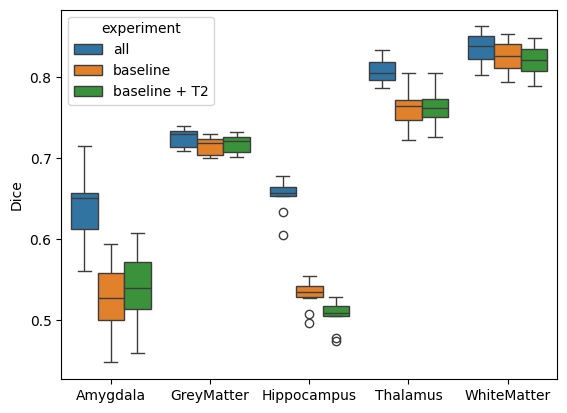

In [32]:
print(wilcoxon(results_mean, 'baseline', 'baseline + T2'))

sns.boxplot(data=results_mean[results_mean.metric == 'DICE'], x='label', y='value', hue='experiment')
plt.ylabel('Dice'); plt.xlabel(''); plt.show()

## 3. Feature importance with SHAP

SHAP splits each prediction into one contribution per feature. The mean absolute SHAP value of a feature, **per
structure**, says how much the forest relies on that feature to recognise the structure.
A sample of test voxels is enough (SHAP is slow).

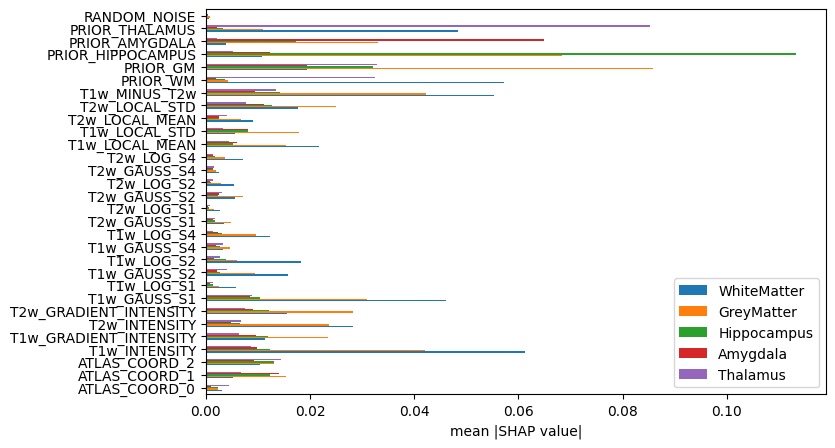

,Background,WhiteMatter,GreyMatter,Hippocampus,Amygdala,Thalamus
ATLAS_COORD_0,0.002077,0.003184,0.002288,0.002294,0.000969,0.004416
ATLAS_COORD_1,0.004123,0.005243,0.015329,0.012303,0.014076,0.006815
ATLAS_COORD_2,0.007486,0.010424,0.013038,0.013145,0.009193,0.014448
T1w_INTENSITY,0.020318,0.061332,0.042041,0.012361,0.009839,0.008738
T1w_GRADIENT_INTENSITY,0.062182,0.011399,0.023541,0.011999,0.009620,0.006364
T2w_INTENSITY,0.010138,0.028290,0.023695,0.006522,0.004811,0.006791
T2w_GRADIENT_INTENSITY,0.072117,0.015510,0.028306,0.012031,0.009027,0.007534
T1w_GAUSS_S1,0.012962,0.046052,0.030919,0.010310,0.008457,0.008809
T1w_LOG_S1,0.003294,0.005852,0.002578,0.001442,0.000809,0.001321
T1w_GAUSS_S2,0.007731,0.015861,0.009354,0.002708,0.002048,0.004038


In [33]:
import shap

names = FEATURE_SETS['all']
forest = train_forest(names, **FOREST)

# a sample of test voxels with the same number of voxels per label (otherwise background dominates)
rng = np.random.default_rng(0)
first = next(iter(test.values()))
sample = np.concatenate([rng.choice(np.flatnonzero(first['y'] == label), 100, replace=False) for label in range(6)])
X_sample = first['X'][sample][:, columns(names)]

shap_values = shap.TreeExplainer(forest).shap_values(X_sample)
shap_values = np.stack(shap_values, axis=-1) if isinstance(shap_values, list) else shap_values  # (voxels, features, classes)

importance = pd.DataFrame({LABELS.get(c, 'Background'): np.abs(shap_values[:, :, i]).mean(axis=0)
                           for i, c in enumerate(forest.classes_)}, index=names)
importance.drop(columns='Background').plot.barh(figsize=(8, 5))
plt.xlabel('mean |SHAP value|'); plt.show()
importance

## 3b. Feature selection with Boruta

Boruta asks for every feature: is it more useful than random noise? It makes a shuffled copy of each feature (a
*shadow* feature: same values, but no relation to the label) and trains a forest on the real and the shadow features,
many times. A real feature is **confirmed** if it is clearly more important than the best shadow feature, **rejected**
if it is clearly less important, and **tentative** if Boruta can't decide within `max_iter` rounds.

SHAP says how much the forest uses a feature, per structure. Boruta gives one yes/no answer for all structures
together. It uses the forest's own (impurity) importance on training voxels, with shallow trees as its authors recommend.

In [34]:
from boruta import BorutaPy

# a subsample of the training voxels keeps it fast: Boruta trains up to max_iter forests on twice the features
rng = np.random.default_rng(0)
subset = rng.choice(len(y_train), min(20000, len(y_train)), replace=False)

boruta_forest = RandomForestClassifier(max_depth=7, class_weight='balanced', n_jobs=-1)  # balanced: small structures count
boruta = BorutaPy(boruta_forest, n_estimators='auto', max_iter=50, random_state=0)
boruta.fit(X_train[subset], y_train[subset])

decision = np.where(boruta.support_, 'confirmed', np.where(boruta.support_weak_, 'tentative', 'rejected'))
boruta_result = pd.DataFrame({'decision': decision, 'rank': boruta.ranking_}, index=FEATURE_NAMES).sort_values('rank')
boruta_result

,decision,rank
ATLAS_COORD_0,confirmed,1
PRIOR_AMYGDALA,confirmed,1
PRIOR_HIPPOCAMPUS,confirmed,1
PRIOR_GM,confirmed,1
PRIOR_WM,confirmed,1
T1w_MINUS_T2w,confirmed,1
T2w_LOCAL_STD,confirmed,1
T2w_LOCAL_MEAN,confirmed,1
T1w_LOCAL_STD,confirmed,1
T1w_LOCAL_MEAN,confirmed,1


Does the confirmed set segment as well as all features? Same forest and seeds as in section 2. With many training
voxels Boruta tends to confirm almost everything: then the two sets are the same, and that is the answer too (every
feature carries *some* information, even if SHAP and leaving groups out show it is small or replaceable).

In [35]:
FEATURE_SETS['boruta'] = [n for n in FEATURE_NAMES if boruta_result.decision[n] == 'confirmed']
print('confirmed:', FEATURE_SETS['boruta'])

boruta_results = []
for seed in SEEDS:
    forest = train_forest(FEATURE_SETS['boruta'], seed=seed, **FOREST)
    boruta_results.append(evaluate(forest, FEATURE_SETS['boruta'], experiment='boruta'))
boruta_results = pd.concat(boruta_results).groupby(['experiment', 'subject', 'label', 'metric'], as_index=False)['value'].mean()
boruta_results = pd.concat([results_mean[results_mean.experiment == 'all'], boruta_results])
print(wilcoxon(boruta_results, 'all', 'boruta'))
summary(boruta_results)

confirmed: ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2', 'T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY', 'T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY', 'T1w_GAUSS_S1', 'T1w_LOG_S1', 'T1w_GAUSS_S2', 'T1w_LOG_S2', 'T1w_GAUSS_S4', 'T1w_LOG_S4', 'T2w_GAUSS_S1', 'T2w_LOG_S1', 'T2w_GAUSS_S2', 'T2w_LOG_S2', 'T2w_GAUSS_S4', 'T2w_LOG_S4', 'T1w_LOCAL_MEAN', 'T1w_LOCAL_STD', 'T2w_LOCAL_MEAN', 'T2w_LOCAL_STD', 'T1w_MINUS_T2w', 'PRIOR_WM', 'PRIOR_GM', 'PRIOR_HIPPOCAMPUS', 'PRIOR_AMYGDALA', 'PRIOR_THALAMUS']
         label  median_diff   p_value
0  WhiteMatter     0.000191  0.001953
1   GreyMatter     0.000138  0.275391
2  Hippocampus     0.000362  0.193359
3     Amygdala     0.000496  0.492188
4     Thalamus    -0.000494  0.105469


experiment                    all         boruta
metric label                                    
DICE   Amygdala     0.638 ± 0.045  0.638 ± 0.045
       GreyMatter   0.725 ± 0.011  0.725 ± 0.011
       Hippocampus   0.653 ± 0.02   0.654 ± 0.02
       Thalamus     0.808 ± 0.015  0.808 ± 0.015
       WhiteMatter  0.837 ± 0.019  0.838 ± 0.019

## 4. Leave one feature group out

How much worse is the segmentation without a group? A large drop means the group carries information the other
features can't replace. Compare with SHAP: a feature can be used a lot (high SHAP) but still be replaceable.

In [36]:
GROUPS = {
    'coordinates': ['ATLAS_COORD_0', 'ATLAS_COORD_1', 'ATLAS_COORD_2'],
    'T1': ['T1w_INTENSITY', 'T1w_GRADIENT_INTENSITY'],
    'T2': ['T2w_INTENSITY', 'T2w_GRADIENT_INTENSITY'],
    'gradients': ['T1w_GRADIENT_INTENSITY', 'T2w_GRADIENT_INTENSITY'],
}

ablation = [evaluate(train_forest(FEATURE_NAMES, **FOREST), FEATURE_NAMES, experiment='all')]
for group, removed in GROUPS.items():
    names = [n for n in FEATURE_NAMES if n not in removed]
    ablation.append(evaluate(train_forest(names, **FOREST), names, experiment=f'without {group}'))
ablation = pd.concat(ablation)
summary(ablation)

experiment                    all     without T1     without T2  \
metric label                                                      
DICE   Amygdala      0.64 ± 0.048   0.64 ± 0.048   0.64 ± 0.047   
       GreyMatter   0.725 ± 0.011  0.722 ± 0.011  0.725 ± 0.011   
       Hippocampus   0.653 ± 0.02   0.643 ± 0.02   0.653 ± 0.02   
       Thalamus      0.81 ± 0.014  0.808 ± 0.014  0.809 ± 0.016   
       WhiteMatter  0.837 ± 0.019   0.838 ± 0.02   0.838 ± 0.02   

experiment         without coordinates without gradients  
metric label                                              
DICE   Amygdala          0.643 ± 0.046      0.63 ± 0.048  
       GreyMatter        0.722 ± 0.011     0.726 ± 0.011  
       Hippocampus       0.654 ± 0.023      0.651 ± 0.02  
       Thalamus          0.804 ± 0.016     0.808 ± 0.015  
       WhiteMatter       0.836 ± 0.019      0.838 ± 0.02

## 5. Robustness to image noise

The frozen forests (trained on clean images) are tested on images with Gaussian noise. Create the noisy features
first with `python extract_features.py --noise 0.1 0.2 0.5` (noise in units of the brain's intensity std).
Which feature set loses most, and which structures suffer?

In [37]:
noise_results = []
for name in ['baseline', 'all']:
    names = FEATURE_SETS[name]
    forest = train_forest(names, **FOREST)
    noise_results.append(evaluate(forest, names, experiment=f'{name}, noise 0'))
    for folder in sorted(glob.glob(os.path.join(FEATURE_DIR, 'noise_*'))):
        level = folder.split('noise_')[-1]
        noise_results.append(evaluate(forest, names, test_data=load_test(folder), experiment=f'{name}, noise {level}'))
noise_results = pd.concat(noise_results)
summary(noise_results)

experiment           all, noise 0 baseline, noise 0
metric label                                       
DICE   Amygdala      0.64 ± 0.048     0.523 ± 0.047
       GreyMatter   0.725 ± 0.011     0.716 ± 0.011
       Hippocampus   0.653 ± 0.02     0.532 ± 0.017
       Thalamus      0.81 ± 0.014     0.763 ± 0.024
       WhiteMatter  0.837 ± 0.019     0.826 ± 0.019

## 6. HD95 for the final comparison

HD95 (`HDRFDST95`, 95th percentile Hausdorff distance in mm) is slower to compute, so it is only computed for the final models. It is `inf` when a structure is not predicted at all.

In [38]:
final = []
for name, names in FEATURE_SETS.items():
    final.append(evaluate(train_forest(names, **FOREST), names, with_hd95=True, experiment=name))
final = pd.concat(final)
summary(final)

experiment                       all        baseline   baseline + T2  \
metric    label                                                        
DICE      Amygdala      0.64 ± 0.048   0.523 ± 0.047   0.537 ± 0.045   
          GreyMatter   0.725 ± 0.011   0.716 ± 0.011   0.718 ± 0.011   
          Hippocampus   0.653 ± 0.02   0.532 ± 0.017   0.508 ± 0.018   
          Thalamus      0.81 ± 0.014   0.763 ± 0.024   0.765 ± 0.021   
          WhiteMatter  0.837 ± 0.019   0.826 ± 0.019   0.822 ± 0.019   
HDRFDST95 Amygdala      4.88 ± 1.486  11.747 ± 1.297  12.244 ± 1.097   
          GreyMatter   1.973 ± 0.085   2.184 ± 0.179    2.22 ± 0.282   
          Hippocampus  9.667 ± 1.507  11.466 ± 1.016  12.679 ± 0.785   
          Thalamus       3.13 ± 0.34   9.269 ± 2.766   8.401 ± 2.478   
          WhiteMatter  1.941 ± 0.185    2.53 ± 0.332   3.237 ± 0.367   

experiment                    boruta  
metric    label                       
DICE      Amygdala     0.634 ± 0.045  
          GreyMatter   0.725 ± 0.011  
          Hippocampus   0.651 ± 0.02  
          Thalamus     0.809 ± 0.015  
          WhiteMatter  0.837 ± 0.019  
HDRFDST95 Amygdala     8.827 ± 2.513  
          GreyMatter   1.973 ± 0.085  
          Hippocampus  10.91 ± 1.993  
          Thalamus     3.146 ± 0.337  
          WhiteMatter  1.941 ± 0.185

## 7. Extended features: does a larger amount of features help?

Create the features first with `python extract_features.py --extended` (written to `features_extended/`). They contain
the 7 basic features (same training voxels, same values) plus four groups:

| group | features | idea |
|---|---|---|
| multi-scale | `T1w/T2w_GAUSS_S1/S2/S4`, `T1w/T2w_LOG_S1/S2/S4` | the smoothed surroundings, and blobs/edges of size σ = 1, 2, 4 mm |
| local statistics | `T1w/T2w_LOCAL_MEAN`, `T1w/T2w_LOCAL_STD` | mean and std in a 5×5×5 cube: uniform tissue or a boundary? |
| T1 − T2 | `T1w_MINUS_T2w` | the two contrasts in one number (a ratio of z-scores would divide by ~0) |
| label prior | `PRIOR_WM`, `PRIOR_GM`, `PRIOR_HIPPOCAMPUS`, `PRIOR_AMYGDALA`, `PRIOR_THALAMUS` | fraction of the 20 training subjects with that label at the voxel (a probabilistic atlas). Training subjects are left out of their own prior; no test label is used |

Plus `RANDOM_NOISE`, a control that carries no information at all.

**From here on `X_train`, `test` and `FEATURE_NAMES` are the extended ones.** The basic features are a subset, so all
feature sets above still work with them.

In [39]:
BASIC = FEATURE_NAMES  # the 7 features of section 0
X_basic = X_train

train = np.load(os.path.join('features_extended', 'train.npz'))
X_train, y_train = train['X'], train['y']
FEATURE_NAMES = list(train['feature_names'])
assert np.allclose(X_train[:, columns(BASIC)], X_basic), 'the basic columns should be the same as in features/'
del X_basic
test = load_test('features_extended')  # replaces the basic test features (memory)

GROUPS_EXTENDED = {
    'multi-scale': [n for n in FEATURE_NAMES if '_GAUSS_' in n or '_LOG_' in n],
    'local statistics': [n for n in FEATURE_NAMES if '_LOCAL_' in n],
    'T1 - T2': ['T1w_MINUS_T2w'],
    'label prior': [n for n in FEATURE_NAMES if n.startswith('PRIOR_')],
}
EXTENDED = BASIC + sum(GROUPS_EXTENDED.values(), [])
EXTENDED_SETS = {'basic': BASIC,
                 **{f'basic + {group}': BASIC + names for group, names in GROUPS_EXTENDED.items()},
                 'extended': EXTENDED}
{name: len(names) for name, names in EXTENDED_SETS.items()}

{'basic': 30,
 'basic + multi-scale': 42,
 'basic + local statistics': 34,
 'basic + T1 - T2': 31,
 'basic + label prior': 35,
 'extended': 52}

Each group is added to the basic features on its own, then all of them together. Same forest and seeds as in
section 2. This takes a while (one forest per set and seed, each predicting all test voxels).

In [40]:
extended_forests = {}  # the seed-0 forest of every set, for the segmentations below
extended_results = []
for name, names in EXTENDED_SETS.items():
    for seed in SEEDS:
        forest = train_forest(names, seed=seed, **FOREST)
        r = evaluate(forest, names, experiment=name)
        r['seed'] = seed
        extended_results.append(r)
        if seed == 0:
            extended_forests[name] = forest
extended_results = pd.concat(extended_results)
extended_mean = extended_results.groupby(['experiment', 'subject', 'label', 'metric'], as_index=False)['value'].mean()
summary(extended_mean)[list(EXTENDED_SETS)]

experiment                  basic basic + multi-scale  \
metric label                                            
DICE   Amygdala     0.638 ± 0.045       0.639 ± 0.045   
       GreyMatter   0.725 ± 0.011       0.723 ± 0.011   
       Hippocampus   0.653 ± 0.02        0.652 ± 0.02   
       Thalamus     0.808 ± 0.015        0.81 ± 0.015   
       WhiteMatter  0.837 ± 0.019       0.837 ± 0.019   

experiment         basic + local statistics basic + T1 - T2  \
metric label                                                  
DICE   Amygdala               0.636 ± 0.043   0.636 ± 0.044   
       GreyMatter             0.724 ± 0.011   0.726 ± 0.011   
       Hippocampus            0.654 ± 0.021    0.651 ± 0.02   
       Thalamus               0.809 ± 0.015   0.807 ± 0.016   
       WhiteMatter            0.836 ± 0.019   0.837 ± 0.019   

experiment         basic + label prior       extended  
metric label                                           
DICE   Amygdala          0.637 ± 0.047  0.636 ± 0.047  
       GreyMatter        0.725 ± 0.011  0.725 ± 0.011  
       Hippocampus       0.648 ± 0.021  0.651 ± 0.021  
       Thalamus          0.804 ± 0.016  0.805 ± 0.016  
       WhiteMatter       0.838 ± 0.019  0.838 ± 0.019

Paired Wilcoxon test of every set against the basic features. With 10 subjects the smallest possible p-value
is 0.002, and these are 25 tests: with a Bonferroni correction only p < 0.05 / 25 = 0.002 counts as significant.

experiment   basic + T1 - T2  basic + label prior  basic + local statistics  \
label                                                                         
Amygdala              -0.002               -0.002                     0.000   
GreyMatter             0.000                0.000                    -0.001   
Hippocampus           -0.003               -0.004                     0.001   
Thalamus              -0.002               -0.004                     0.000   
WhiteMatter            0.000                0.001                    -0.001   

experiment   basic + multi-scale  extended  
label                                       
Amygdala                   0.002    -0.003  
GreyMatter                -0.002    -0.000  
Hippocampus               -0.001    -0.003  
Thalamus                   0.001    -0.004  
WhiteMatter               -0.000     0.001  
experiment   basic + T1 - T2  basic + label prior  basic + local statistics  \
label                                               

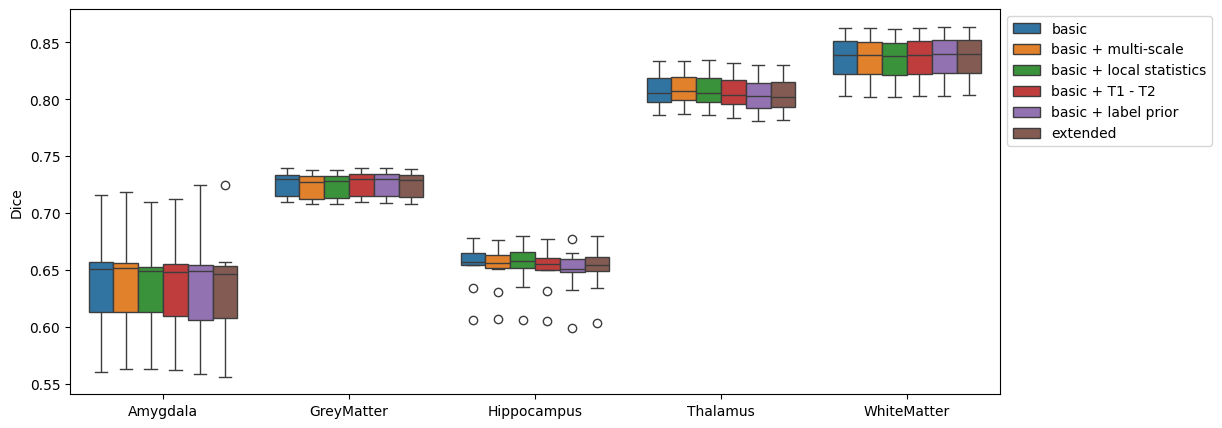

In [41]:
tests = pd.concat([wilcoxon(extended_mean, 'basic', name).assign(experiment=name)
                   for name in EXTENDED_SETS if name != 'basic'])
print(tests.pivot(index='label', columns='experiment', values='median_diff').round(3))
print(tests.pivot(index='label', columns='experiment', values='p_value').round(4))

plt.figure(figsize=(12, 5))
sns.boxplot(data=extended_mean[extended_mean.metric == 'DICE'], x='label', y='value', hue='experiment',
            hue_order=list(EXTENDED_SETS))
plt.ylabel('Dice'); plt.xlabel(''); plt.legend(bbox_to_anchor=(1, 1)); plt.show()

### The random control

A forest on all extended features plus `RANDOM_NOISE`. Every real feature with an importance close to the noise
feature's is useless to the forest. Boruta (section 3b) does the same test more carefully, with a shuffled copy of
every feature.

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

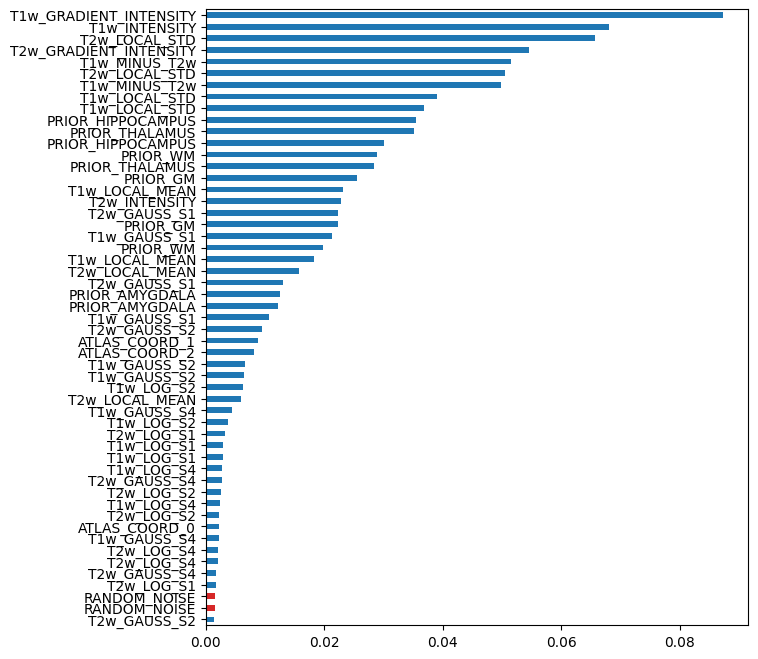

In [43]:
names = EXTENDED + ['RANDOM_NOISE']
forest = train_forest(names, **FOREST)
importance = pd.Series(forest.feature_importances_, index=names).sort_values()
importance.plot.barh(figsize=(7, 8), color=['tab:red' if n == 'RANDOM_NOISE' else 'tab:blue' for n in importance.index])
plt.axvline(importance['RANDOM_NOISE'], color='tab:red', linestyle='--')
plt.xlabel('forest importance (mean decrease in impurity)'); plt.show()

boruta = BorutaPy(RandomForestClassifier(max_depth=7, class_weight='balanced', n_jobs=-1), n_estimators='auto',
                  max_iter=50, random_state=0)
boruta.fit(X_train[subset][:, columns(names)], y_train[subset])
decision = np.where(boruta.support_, 'confirmed', np.where(boruta.support_weak_, 'tentative', 'rejected'))
pd.DataFrame({'decision': decision, 'rank': boruta.ranking_}, index=names).sort_values('rank')

### HD95 of the basic and the extended features

In [44]:
final_extended = pd.concat([evaluate(extended_forests[name], EXTENDED_SETS[name], with_hd95=True, experiment=name)
                            for name in ['basic', 'extended']])
summary(final_extended)

experiment                     basic       extended
metric    label                                    
DICE      Amygdala      0.64 ± 0.048  0.632 ± 0.047
          GreyMatter   0.725 ± 0.011  0.725 ± 0.011
          Hippocampus   0.653 ± 0.02   0.65 ± 0.021
          Thalamus      0.81 ± 0.014  0.805 ± 0.016
          WhiteMatter  0.837 ± 0.019  0.838 ± 0.019
HDRFDST95 Amygdala      4.88 ± 1.486  4.993 ± 1.623
          GreyMatter   1.973 ± 0.085  1.973 ± 0.085
          Hippocampus  9.667 ± 1.507  10.89 ± 1.799
          Thalamus       3.13 ± 0.34  3.223 ± 0.357
          WhiteMatter  1.941 ± 0.185  1.941 ± 0.185

### Look at the segmentations

Writes the T1w image, the ground truth and the segmentations of the basic and the extended forest of one test subject
as `.mha` files to `segmentations/`. Open them in [ITK-SNAP](http://www.itksnap.org) or [3D Slicer](https://www.slicer.org):
the T1w image as the main image, the others as segmentations (labels) on top. All are in atlas space.

In [45]:
SEGMENTATION_DIR = 'segmentations'
subject = list(test)[0]  # any test subject, or loop over all of them
data = test[subject]
os.makedirs(SEGMENTATION_DIR, exist_ok=True)

volumes = {'ground truth': data['y']}
for name in ['basic', 'extended']:
    volumes[name] = extended_forests[name].predict(data['X'][:, columns(EXTENDED_SETS[name])])

t1 = to_image(data['X'][:, columns(['T1w_INTENSITY'])[0]], data['brain_index'], dtype=np.float32)
sitk.WriteImage(t1, os.path.join(SEGMENTATION_DIR, f'{subject}_T1w.mha'))
for name, labels in volumes.items():
    sitk.WriteImage(to_image(labels, data['brain_index']),
                    os.path.join(SEGMENTATION_DIR, f'{subject}_{name.replace(" ", "_")}.mha'))
print('written to', SEGMENTATION_DIR, ':', sorted(f for f in os.listdir(SEGMENTATION_DIR) if f.startswith(subject)))

written to segmentations : ['117122_T1w.mha', '117122_basic.mha', '117122_extended.mha', '117122_ground_truth.mha']


The same in the notebook: a coronal and an axial slice through the hippocampus, with the Dice of every structure
of this subject in the titles.

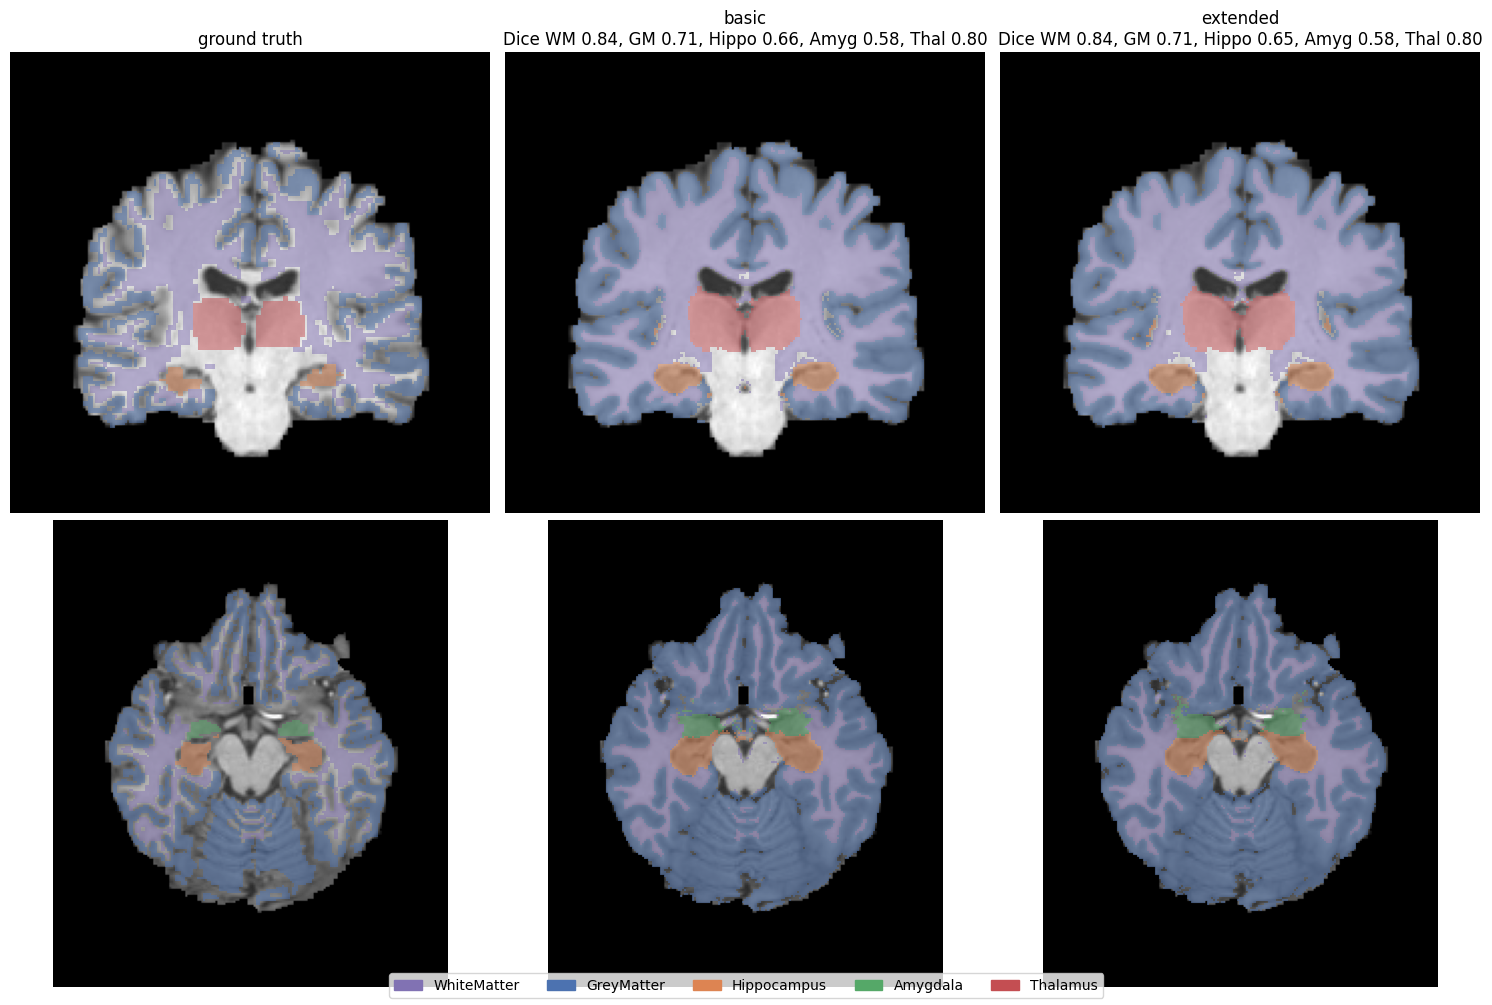

In [46]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

COLORS = ['#8172b3', '#4c72b0', '#dd8452', '#55a868', '#c44e52']  # WM, GM, hippocampus, amygdala, thalamus
SHORT = {1: 'WM', 2: 'GM', 3: 'Hippo', 4: 'Amyg', 5: 'Thal'}
t1_volume = sitk.GetArrayFromImage(t1)  # (z, y, x)
brain = sitk.GetArrayFromImage(to_image(np.ones(len(data['brain_index'])), data['brain_index'])) > 0
t1_volume[~brain] = t1_volume[brain].min()  # black outside the brain (0 is the mean intensity after z-scoring)
label_volumes = {name: sitk.GetArrayFromImage(to_image(labels, data['brain_index'])) for name, labels in volumes.items()}
z, y, x = np.argwhere(label_volumes['ground truth'] == 3).mean(axis=0).astype(int)  # centre of the hippocampus

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for column, (name, volume) in enumerate(label_volumes.items()):
    for row, cut in enumerate([np.s_[:, y, :], np.s_[z, :, :]]):  # coronal, axial
        ax = axes[row, column]
        ax.imshow(t1_volume[cut], cmap='gray', origin='lower')
        ax.imshow(np.ma.masked_equal(volume[cut], 0), cmap=ListedColormap(COLORS), vmin=0.5, vmax=5.5,
                  alpha=0.5, origin='lower', interpolation='nearest')
        ax.axis('off')
    title = name if name == 'ground truth' else name + '\nDice ' + ', '.join(
        f'{SHORT[label]} {dice(volumes[name], data["y"], label):.2f}' for label in LABELS)
    axes[0, column].set_title(title)
fig.legend(handles=[Patch(color=c, label=LABELS[i + 1]) for i, c in enumerate(COLORS)], loc='lower center', ncol=5)
plt.tight_layout(); plt.show()